In [2]:
import pandas as pd
from pathlib import Path

files = sorted(Path("../data/raw").glob("*.csv"))
df = pd.concat(pd.read_csv(f) for f in files)
df["SETTLEMENTDATE"] = pd.to_datetime(df["SETTLEMENTDATE"])
df = df.set_index("SETTLEMENTDATE").sort_index()
df.head()

,REGION,TOTALDEMAND,RRP,PERIODTYPE
SETTLEMENTDATE,,,,
2025-08-01 00:05:00,SA1,1692.01,180.86,TRADE
2025-08-01 00:10:00,SA1,1687.43,207.74,TRADE
2025-08-01 00:15:00,SA1,1677.01,178.70,TRADE
2025-08-01 00:20:00,SA1,1683.64,176.50,TRADE
2025-08-01 00:25:00,SA1,1675.67,263.72,TRADE


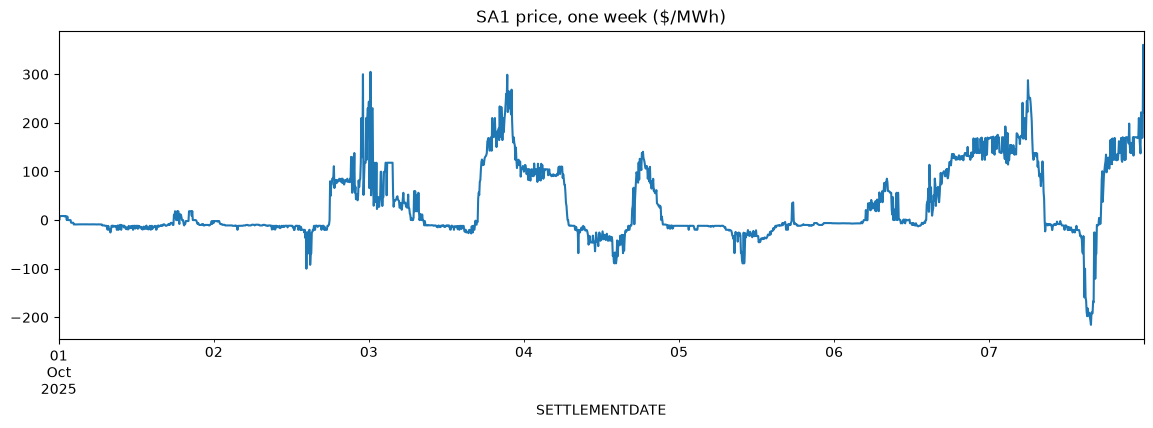

In [5]:
df.loc["2025-10-01":"2025-10-07", "RRP"].plot(figsize=(14,4), title="SA1 price, one week ($/MWh)");

## 1. Timezone

**Finding:** The timestamps are in AEMO market time (AEST, UTC+10), not Adelaide local time. Market time has no daylight saving.

**Evidence:**
- AEMO's documentation says the NEM runs on market time.
- I checked 5 Oct 2025, when SA clocks moved forward an hour at 2am. Between 00:00 and 04:00 there are 49 rows and all 48 gaps are exactly 5 minutes, so no hour is missing. The data doesn't follow daylight saving.
- `SETTLEMENTDATE` marks the end of each 5-minute interval, so 12:05 covers 12:00 to 12:05.

**What this means:**
- During Adelaide summer (UTC+10:30), local time is 30 minutes ahead of market time. In winter (UTC+9:30) it's 30 minutes behind.
- I'll keep all data in market time internally and only convert to Adelaide time for display.
- When I join weather data in M2, I'll convert it to market time first so the features line up.

In [9]:
oct5 = df.loc["2025-10-05 00:00":"2025-10-05 04:00"]

print(f"Rows: {len(oct5)}")
print(oct5.index.to_series().diff().value_counts())

Rows: 49
SETTLEMENTDATE
0 days 00:05:00    48
Name: count, dtype: int64


## 2. Gaps

**Finding:** The data is complete. Every 5-minute interval from 1 Aug to 31 Oct 2025 is present, with no duplicates and no missing values.

**Evidence:**
- 1 Aug 00:05 to 1 Nov 00:00 is 92 days × 288 intervals = 26,496 expected rows. I have 26,496.
- All 26,495 gaps between timestamps are exactly 5 minutes, so nothing is missing or duplicated.
- `df.isna().sum()` shows no missing values in any column.

**What this means:**
- I can build lag features (like "price 1 hour ago") by shifting rows without filling gaps first.
- This is only 3 months though. When I pull more history in M5, the ingester should check for gaps automatically instead of assuming the data is clean.

In [12]:
df.index.min(), df.index.max()

(Timestamp('2025-08-01 00:05:00'), Timestamp('2025-11-01 00:00:00'))

In [11]:
df.index.to_series().diff().value_counts()

SETTLEMENTDATE
0 days 00:05:00    26495
Name: count, dtype: int64

In [13]:
df.isna().sum()

REGION         0
TOTALDEMAND    0
RRP            0
PERIODTYPE     0
dtype: int64

## 3. Extremes

*All prices in AUD/MWh.*

**Finding:** SA prices are negative a third of the time, and there are rare but extreme spikes. The distribution looks like two regimes: renewables pushing prices just below 0, and gas setting prices around 100 to 200.

**Evidence:**
- 34.4% of intervals are negative. The most common prices are around -10 to -20.
- 1.0% of intervals are above 300 and only 0.02% (about 5 intervals) are above 1,000.
- The 99th percentile is 300 but the max is 14,500. The min is -576.
- Mean 65 vs median 53, with a std of 126, so a few spikes have a big effect on averages.
- The histogram has sharp bars around 140 and 165, which I think come from generators bidding at fixed price bands.

**What this means:**
- The battery has a lot of cheap (or paid) charging opportunities.
- A plain average error metric would be dominated by a handful of spikes. In M2 I'll use MAE and report spike and non-spike intervals separately.
- I might need to cap or transform prices for training, or treat spike prediction as its own problem.
- With only 3 months of data, I've seen very few spikes. I'll need more history before I can say anything reliable about them.

In [15]:
rrp = df["RRP"]

print(f"Negative:     {(rrp < 0).mean():.1%}")
print(f"Above $300:   {(rrp > 300).mean():.1%}")
print(f"Above $1000:  {(rrp > 1000).mean():.2%}")
print(f"Min: ${rrp.min():,.0f}   Max: ${rrp.max():,.0f}")
rrp.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

Negative:     34.4%
Above $300:   1.0%
Above $1000:  0.02%
Min: $-576   Max: $14,500


count    26496.000000
mean        64.957411
std        126.322300
min       -575.690000
1%         -90.498500
5%         -25.510000
25%        -11.000000
50%         52.825000
75%        125.000000
95%        215.590000
99%        299.990000
max      14500.000000
Name: RRP, dtype: float64

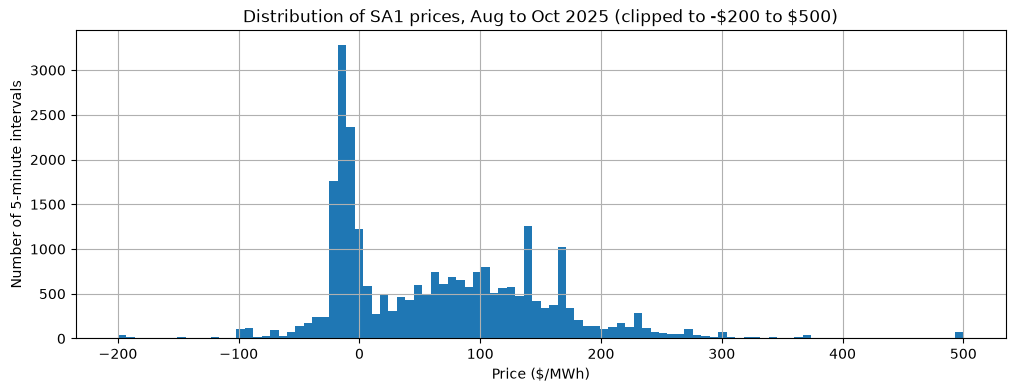

In [24]:
ax = rrp.clip(-200, 500).hist(bins=100, figsize=(12, 4))
ax.set_xlabel(r"Price (\$/MWh)")
ax.set_ylabel("Number of 5-minute intervals")
ax.set_title(r"Distribution of SA1 prices, Aug to Oct 2025 (clipped to -\$200 to \$500)");

## 4. Daily shape

*All prices in AUD/MWh. Hours are market time (UTC+10).*

**Finding:** There's a clear and reliable daily pattern. Prices are lowest in the middle of the day and highest in the early evening, which gives a battery a strong charge/discharge cycle.

**Evidence:**
- Cheapest hour is 13:00 (median -14). From 9:00 to 15:00 the median stays below 0 and the 25th to 75th percentile band is very narrow, so it's cheap almost every day.
- Most expensive hour is 18:00 (median 135). From 17:00 to 20:00 the median stays above 110, but the band is wider.
- The spread between the cheapest and most expensive hour is 149.
- Prices rise by about 115 between 16:00 and 17:00.
- Overnight prices are moderate (median 65 to 85) but very spread out, from about 0 to 140.

**What this means:**
- The arbitrage idea works: charge from roughly 9:00 to 15:00, discharge from roughly 17:00 to 20:00.
- The midday trough is easy to predict. The evening peak and overnight prices are harder, so that's where forecasting adds value.
- The wide overnight band is probably driven by wind, so weather data should be a key feature in M2.
- These hours are market time. During daylight saving, Adelaide local time is 30 minutes ahead.

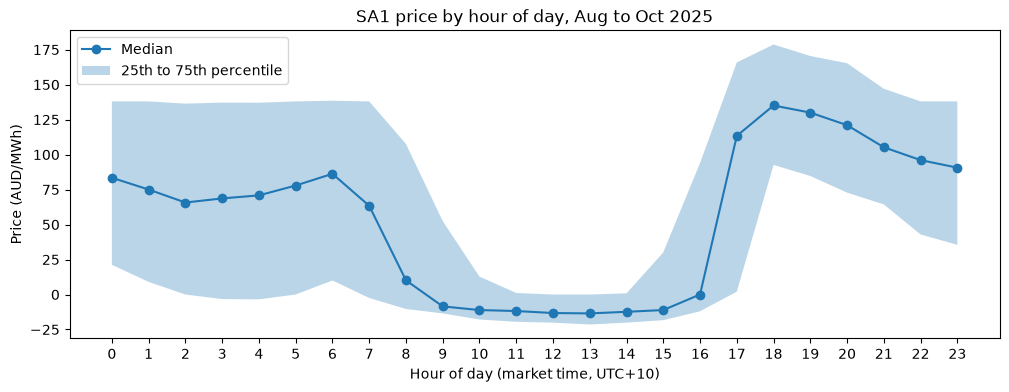

In [25]:
hourly = df.groupby(df.index.hour)["RRP"]

ax = hourly.median().plot(figsize=(12, 4), marker="o", label="Median")
ax.fill_between(range(24), hourly.quantile(0.25), hourly.quantile(0.75), alpha=0.3, label="25th to 75th percentile")
ax.set_xlabel("Hour of day (market time, UTC+10)")
ax.set_ylabel("Price (AUD/MWh)")
ax.set_title("SA1 price by hour of day, Aug to Oct 2025")
ax.set_xticks(range(24))
ax.legend();

In [26]:
summary = hourly.median()
print(f"Cheapest hour: {summary.idxmin()}:00, median {summary.min():.0f}")
print(f"Most expensive hour: {summary.idxmax()}:00, median {summary.max():.0f}")
print(f"Spread: {summary.max() - summary.min():.0f}")

Cheapest hour: 13:00, median -14
Most expensive hour: 18:00, median 135
Spread: 149
